# Hälsostudie
Av: Lovis Wikström

## Del 2 - Kodstruktur och fördjupad analys

### 1. Introduktion
I denna rapporten undersöks data från en hälsostudie med 800 deltagare.
Vårt syfte är att analysera hälsorelaterade faktorer samt undersöka eventuella samband mellan exempelvis ålder, vikt, blodtryck, rökning och sjukdomsförekomst. 
Vi genomför analysen med hjälp av Python och vi använder oss av beskrivande statistik, visualiseringar, simuleringar, konfidensintervall och hypotesprövning för att undersöka och tolka datan.



### 2. Importering och inläsning

Vi importerar de moduler och funktioner som behövs för analysen. Datan läses in med hjälp av funktionen load_data() från io_utils.py

In [120]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

from io_utils import load_data
import metrics
import viz
import analyzer

df = load_data()
health = analyzer.HealthAnalyzer(df)

### 3. Kontroll av datasetet

### 3. Översikt
Vi börjar med att undersöka datan vi har, här går vi igenom och tittar på och kontrollerar det vi jobbar med och ser till att allt är som det ska, att det inte finns dubletter och så vidare.
Vi börjar med att titta på hur många rader och kolumner vi har, samt de fem översta raderna för att få en idé om vad det är för data vi har att arbeta med.

In [121]:
print("Antal rader och kolumner:", df.shape)
df.head()

Antal rader och kolumner: (800, 9)


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


Här kontrolleras saknade värden och dubletter, samt kikar på deskriptiv statistik. 
Vi kan konstatera att det inte saknas några värden och att alla rader är unika, alltså förekommer inga dubletter.

För enkelhetens skull avrundar vi till två decimaler för att få en bättre överblick.

In [122]:
display(
    metrics.descriptive_statistics(df).round(2).rename(
        index={"50%": "median"}
    )
)

print("Saknade värden:")
print(df.isna().sum())

print("Dubletter:", df.duplicated().sum())

,age,weight,height,systolic_bp,cholesterol,disease
mean,49.43,73.41,171.85,149.18,4.93,0.06
median,50.00,73.20,171.35,149.40,4.97,0.00
min,18.00,33.70,144.40,106.80,2.50,0.00
max,90.00,114.40,200.40,185.90,7.88,1.00


Saknade värden:
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64
Dubletter: 0


Datasetet består av 800 rader och 9 kolumner. 
Vid kontroll av datakvaliteten upptäcktes inga saknade värden eller dubletter, vilket innebär att samtliga observationer är unika och kompletta.

Medelåldern bland deltagarna är cirka 49,43 år och medianåldern är 50 år. Medelvikten är 73,41 kg och det genomsnittliga systoliska blodtrycket är 149,18 mmHg.


Genom att jämföra medelvärde och median kan vi få en uppfattning om hur värdena är fördelade, och vi kan se att de inte skiljer sig så mycket, vilket man kan tolka som att det är en jämn fördelning i vår data.

Här gör vi en sammanställning av median, medelvärde, minsta och största värde i variablerna. 
Beräkningarna görs med funktion från modulen metrics.py och resultaten avrundar vi till två decimaler.

In [123]:
display(
    metrics.descriptive_statistics(df).round(2)
)

,age,weight,height,systolic_bp,cholesterol,disease
mean,49.43,73.41,171.85,149.18,4.93,0.06
median,50.00,73.20,171.35,149.40,4.97,0.00
min,18.00,33.70,144.40,106.80,2.50,0.00
max,90.00,114.40,200.40,185.90,7.88,1.00


### 4. Visualisering
Här undersöker vi deltagarnas hälsodata med hjälp av visualiseringar i fyra olika diagram.
##### 4.1. Histogram: Fördelningen av systoliskt blodtryck. 

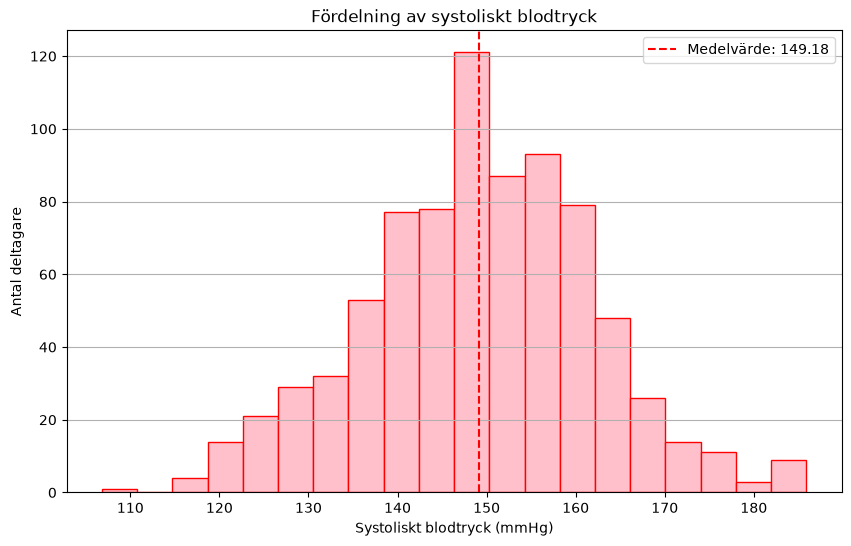

In [124]:
viz.hist_bp(df)

Histogrammet visar hur deltagarnas systoliska blodtryck är fördelat. Genom att visualisera fördelningen blir det lättare att se var de flesta observationerna ligger och om det finns några ovanligt höga eller låga värden.

Medelvärdet för det systoliska blodtrycket är cirka 149,18 mmHg. Diagrammet ger en bild av hur blodtrycksvärdena varierar runt medelvärdet.
Vi ser medelvärdet markerat i histogrammet. 

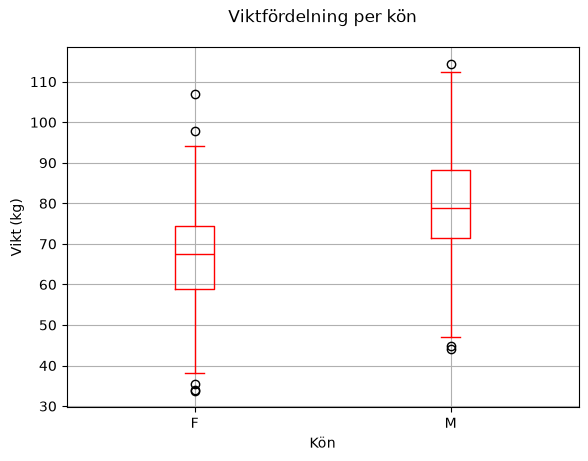

In [125]:
viz.weight_by_sex(df)

Här använder vi ett låddiagram för att jämföra viktfördelningen mellan kvinnor och män i detta dataset.

Genom att jämföra medianen, spridningen och eventuella avvikande värden kan vi identifiera om det finns skillnader mellan grupperna.

##### 4.3. Stapeldiagram: Fördelningen mellan rökare/icke-rökare.

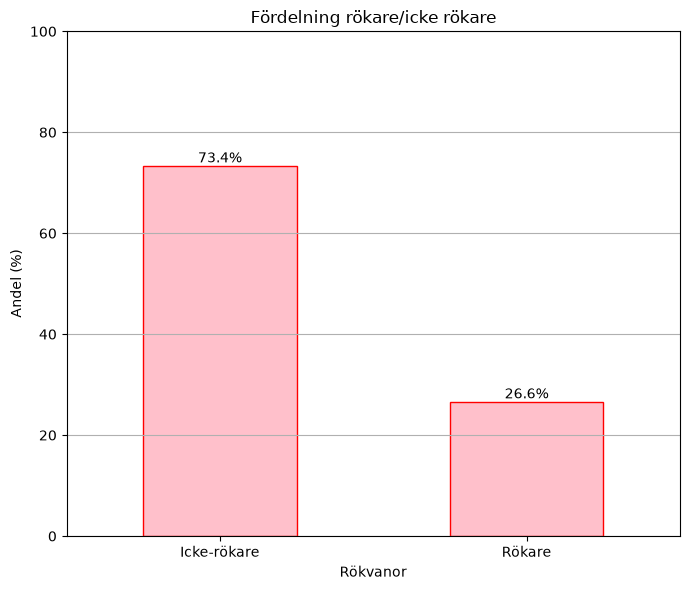

In [126]:
viz.bar_smoker(df)

Stapeldiagrammet visar fördelningen mellan rökare och icke-rökare bland deltagarna i detta dataset.

Av totalt 800 deltagare är 213 (26,6%) rökare och 587 (73,4%) icke-rökare. Det innebär att majoriteten av deltagarna i undersökningen inte röker.

Diagrammet gör det enkelt att jämföra gruppernas storlek och ger oss en överblick över hur rökvanorna är fördelade i detta dataset.

##### 4.4. Spridningsdiagram: Sambandet mellan ålder och systoliskt blodtryck.
Visas här med den linjära regressionen. 

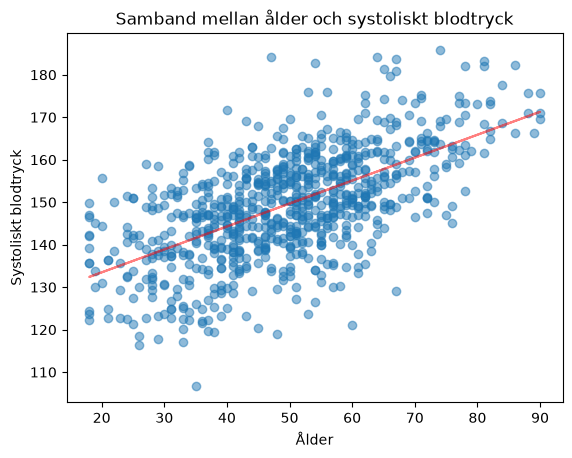

Det förväntade systoliska blodtrycket ökar med cirka 0.54 mmHg / år.


In [127]:
health.scat_age_bp()

Spridningsdiagrammet visar sambandet mellan deltagarnas ålder och systoliskt blodtryck.

Regressionslinjen har en positiv lutning på cirka 0,54, vilket innebär att det förväntade systoliska blodtrycket enligt modellen ökar med ungefär 0,54 mmHg för varje ytterligare levnadsår.

Detta tyder på ett positivt samband mellan ålder och systoliskt blodtryck i datasetet. Observera dock att ett samband inte automatiskt innebär att ålder är den enda faktorn som påverkar blodtrycket.

Spridningen mellan observationerna visar också att deltagare i samma ålder kan ha olika blodtryck.

### 4.5. Spridningsdiagram: sambandet mellan BMI och systoliskt blodtryck.

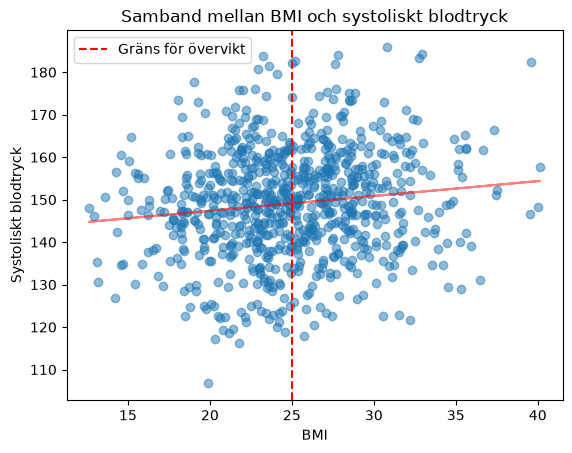

För varje ökning med 1 BMI-enhet förändras det förväntade systoliska blodtrycket med cirka 0.35 mmHg.


In [128]:
health.scat_bmi_bp()

Diagrammet visar sambandet mellan deltagarnas BMI och systoliska blodtryck. Den röda regressionslinjen visar den uppskattade linjära trenden i datan.

Den streckade röda linjen vid BMI 25 markerar gränsen mellan normalvikt och övervikt enligt BMI-skalan.

Regressionslinjens lutning visar hur det förväntade systoliska blodtrycket förändras när BMI ökar med en enhet. 

### 5. Sjukdomsförekomst
I denna delen kikar vi närmre på sjukdomsförekomsten. 
Vi tar reda på hur ofta det förekommer och undersöker om det finns någon effekt av slumpmässig variation.

In [129]:
disease_rate = metrics.disease_probability(df)
disease_count = metrics.disease_amount(df)

print(f"Andel med sjukdom: {disease_rate:.2%} av {len(df)} deltagare.")
print(f"Antal deltagare med sjukdom: {disease_count}.")

Andel med sjukdom: 5.88% av 800 deltagare.
Antal deltagare med sjukdom: 47.


Vi undersöker slumpmässig variation genom att göra en simulering.

In [130]:
sim_disease = metrics.probability_simulation(df)

sim_rate = sim_disease.mean()
dif_disease = (disease_rate - sim_rate) * 100

print(f"Dokumenterad andel med sjukdom: {disease_rate:.2%}")
print(f"Simulerad andel med sjukdom: {sim_rate:.2%}")
print(f"Skillnaden mellan dokumenterad och simulerad andel: {dif_disease:.2f} procentenheter.")

Dokumenterad andel med sjukdom: 5.88%
Simulerad andel med sjukdom: 5.40%
Skillnaden mellan dokumenterad och simulerad andel: 0.47 procentenheter.


Den dokumenterade sjukdomsförekomsten i detta dataset är 5,88%, vilket motsvarar 47 av 800 deltagare.

För att undersöka hur slumpmässig variation kan påverka resultatet genomfördes en simulering med 1 000 observationer. I simuleringen blev sjukdomsförekomsten 5,40%.

Skillnaden mellan den dokumenterade och simulerade andelen är ungefär 0,47 procentenheter, vilket visar att vi har fått ett resultat nära den verkliga sjukdomsförekomsten.

Detta visar att resultatet kan variera något på grund av slumpmässiga faktorer, även när samma sannolikhet används som utgångspunkt. Den simulerade andelen behöver därför inte bli exakt densamma som den observerade andelen.

### 6. Health Analyzer
För att samla delar av analysen har vi skapat klassen HealthAnalyzer i modulen analyzer.py.

Klassen sparar datasetet och använder funktioner från metrics.py och viz.py för att utföra beräkningar och skapa visualiseringar.

Genom att samla funktionerna i en klass blir koden mer strukturerad och återanvändbar. Det gör det även enklare att genomföra analyserna på nytt med samma dataset och därmed underlätta reproducerbarheten.

I rapporten använder vi klassen för att hämta deskriptiv statistik samt visa sambanden mellan ålder och blodtryck och mellan BMI och blodtryck. På så sätt demonstrerar vi hur flera olika analyser kan utföras genom samma klass utan att behöva anropa varje funktion separat.

In [131]:
health.get_summary()

,age,weight,height,systolic_bp,cholesterol,disease
mean,49.42625,73.413,171.84925,149.178625,4.92915,0.05875
median,50.00000,73.200,171.35000,149.400000,4.97000,0.00000
min,18.00000,33.700,144.40000,106.800000,2.50000,0.00000
max,90.00000,114.400,200.40000,185.900000,7.88000,1.00000
